# Laboratorium 2B – YOLO i podejście hybrydowe (wariant CPU, bez fine-tuningu)

**Cel:** rozwiązać ten sam problem co w laboratorium 2A za pomocą gotowego modelu YOLO i sprawdzić podejście hybrydowe, w którym YOLO lokalizuje sygnalizator, a kolor rozpoznaje metoda klasyczna.

**Zakres (wariant bez GPU):** porównanie dotyczy wyłącznie sygnalizatorów. Standardowy YOLO wytrenowany na COCO nie ma klasy obejmującej wszystkie znaki drogowe, dlatego znaki są omówione tylko w zadaniu 1.

**Plan i pytania badawcze:**

| Krok | Pytanie | Hipoteza |
|---|---|---|
| 1. YOLO z COCO | Co gotowy model wykrywa w BDD100K? | Wykrywa sygnalizatory i znaki STOP, ale nie pozostałe znaki, bo nie zna takich klas. |
| 2. Rozdzielczość wejścia | Czy domyślne 640 px wystarcza? | Nie – zmniejszenie obrazu 1280×720 do 640 px sprawia, że małe sygnalizatory stają się niewidoczne dla sieci. |
| 3. Kolor (hybryda) | Czy metoda koloru z 2A działa na ramkach z YOLO? | Działa gorzej, bo była uczona na ramkach z adnotacji, a ramki YOLO mają inny kształt. |
| 4. Porównanie z 2A | Które podejście jest lepsze? | YOLO lepiej lokalizuje większe obiekty i działa szybciej, metoda klasyczna lepiej radzi sobie z małymi świecącymi lampami. |

**Zasady:** te same obrazy i ten sam zbiór testowy co w 2A, próg IoU ≥ 0,5, wszystkie parametry dobierane tylko na train/val, czas mierzony na CPU.

**Uruchomienie:** `uv sync`, następnie `uv run jupyter lab`. W katalogu muszą być pliki z laboratorium 2A: `predictions_test_lab2A.json` i `test_images.json`, opcjonalnie `fps_lab2A.json`. Wykresy zapisywane są do katalogu `figures/`.

## 0. Konfiguracja

In [1]:
import itertools
import json
import os
import pickle
import random
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from tqdm.auto import tqdm
from ultralytics import YOLO

DATA_ROOT = "100k"
IMG_DIR = {"train": os.path.join(DATA_ROOT, "train"), "val": os.path.join(DATA_ROOT, "val")}
LBL_DIR = IMG_DIR

N_TRAIN, N_VAL, N_TEST = 2000, 500, 500
SEED = 42
CACHE_DIR = "cache"
FIG_DIR = "figures"

MODEL_NAME = "yolov5su.pt"
IMG_SIZES = [640, 960, 1280]      # badane rozmiary wejścia YOLO
CONF_MIN = 0.01                   # minimalna pewność zapisywanych detekcji
DEVICE = "cpu"                    # wariant CPU – czas mierzony na procesorze
COCO_TRAFFIC_LIGHT = 9
COCO_STOP_SIGN = 11

COLORS = ["red", "yellow", "green", "unknown"]
COLOR_MAP = {"red": "red", "yellow": "yellow", "green": "green", "none": "unknown"}

random.seed(SEED)
np.random.seed(SEED)
os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


def load_or_compute(name, compute, *args):
    """Wczytuje wynik z cache albo liczy go i zapisuje. Nazwa pliku zawiera rozmiary podziału."""
    path = os.path.join(CACHE_DIR, f"{name}_{N_TRAIN}_{N_VAL}_{N_TEST}_{SEED}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    result = compute(*args)
    with open(path, "wb") as f:
        pickle.dump(result, f)
    return result


def save_figure(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")

### Dane

Podział jest identyczny jak w laboratorium 2A (te same rozmiary i to samo ziarno losowania): train i val pochodzą z oficjalnego `train`, test z oficjalnego `val`. Zgodność zbioru testowego sprawdzana jest z plikiem `test_images.json` z 2A.

In [2]:
def load_label(path):
    """Ramki znaków i sygnalizatorów dla jednego obrazu."""
    with open(path) as f:
        d = json.load(f)
    boxes = []
    for obj in d["frames"][0]["objects"]:
        if obj["category"] not in ("traffic sign", "traffic light") or "box2d" not in obj:
            continue
        b = obj["box2d"]
        attr = obj.get("attributes", {})
        cls = obj["category"].replace(" ", "_")
        color = None
        if cls == "traffic_light":
            color = COLOR_MAP.get(attr.get("trafficLightColor", "none"), "unknown")
        boxes.append({"cls": cls, "box": [b["x1"], b["y1"], b["x2"], b["y2"]], "color": color})
    return {"boxes": boxes, "attrs": d.get("attributes", {})}


def load_split(split, names):
    data = {}
    for name in names:
        lbl_path = os.path.join(LBL_DIR[split], name + ".json")
        img_path = os.path.join(IMG_DIR[split], name + ".jpg")
        if os.path.exists(lbl_path) and os.path.exists(img_path):
            item = load_label(lbl_path)
            item["img_path"] = img_path
            data[name] = item
    return data


def list_names(split):
    return sorted(f[:-5] for f in os.listdir(LBL_DIR[split]) if f.endswith(".json"))


rng = random.Random(SEED)
pool = rng.sample(list_names("train"), N_TRAIN + N_VAL)
train = load_split("train", pool[:N_TRAIN])
val = load_split("train", pool[N_TRAIN:])
test = load_split("val", rng.sample(list_names("val"), N_TEST))
ALL = {**train, **val, **test}
print(f"train: {len(train)}, val: {len(val)}, test: {len(test)}")

with open("test_images.json") as f:
    test_lab2A = json.load(f)
assert sorted(test) == sorted(test_lab2A), "Zbiór testowy różni się od zbioru z laboratorium 2A"
print("Zbiór testowy zgodny z laboratorium 2A")


def gt_boxes(item, cls):
    boxes = [b["box"] for b in item["boxes"] if b["cls"] == cls]
    return np.array(boxes, np.float32).reshape(-1, 4)


def gt_colors(item):
    return [b["color"] for b in item["boxes"] if b["cls"] == "traffic_light"]


def box_size(box):
    return np.sqrt(max((box[2] - box[0]) * (box[3] - box[1]), 0))

train: 2000, val: 500, test: 500
Zbiór testowy zgodny z laboratorium 2A


### Sygnalizatory w zbiorze testowym

Przed porównaniem metod warto przypomnieć, jakie obiekty są do wykrycia. Rozmiar sygnalizatora jest kluczowy dla YOLO, ponieważ model domyślnie zmniejsza obraz 1280×720 do 640 px, czyli dwukrotnie. Sygnalizator o rozmiarze 12 px ma wtedy dla sieci tylko 6 px.

Sygnalizatory w zbiorze testowym: 1421


udział
rozmiar [px] (0, 8]       0.024
             (8, 16]      0.437
             (16, 32]     0.400
             (32, 64]     0.132
             (64, 1000]   0.008
kolor        green        0.419
             unknown      0.315
             red          0.246
             yellow       0.020
pora dnia    night        0.474
             daytime      0.420
             dawn/dusk    0.106

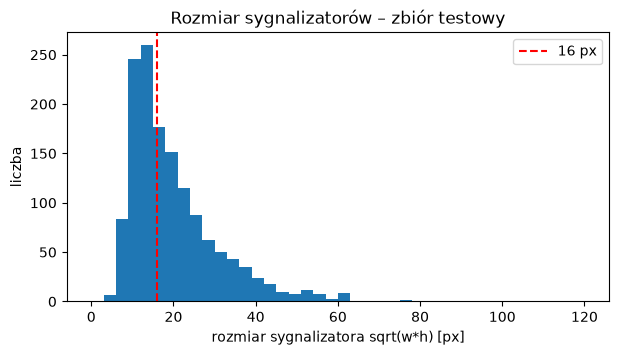

In [3]:
rows = []
for split, data in [("train", train), ("val", val), ("test", test)]:
    for item in data.values():
        for b in item["boxes"]:
            if b["cls"] == "traffic_light":
                rows.append({"split": split, "size": box_size(b["box"]), "color": b["color"],
                             "timeofday": item["attrs"].get("timeofday")})
lights_df = pd.DataFrame(rows)
lights_df["rozmiar"] = pd.cut(lights_df["size"], bins=[0, 8, 16, 32, 64, 1000])

test_lights = lights_df[lights_df.split == "test"]
print(f"Sygnalizatory w zbiorze testowym: {len(test_lights)}")
summary = pd.concat([
    test_lights["rozmiar"].value_counts(normalize=True).sort_index(),
    test_lights["color"].value_counts(normalize=True),
    test_lights["timeofday"].value_counts(normalize=True),
], keys=["rozmiar [px]", "kolor", "pora dnia"]).rename("udział")
display(summary.round(3).to_frame())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(test_lights["size"], bins=40, range=(0, 120))
ax.axvline(16, color="r", ls="--", label="16 px")
ax.set_xlabel("rozmiar sygnalizatora sqrt(w*h) [px]")
ax.set_ylabel("liczba")
ax.set_title("Rozmiar sygnalizatorów – zbiór testowy")
ax.legend()
save_figure("rozmiar_sygnalizatorow_test")
plt.show()

### Metryki

Te same zasady co w laboratorium 2A: predykcja jest TP, jeżeli jej IoU z niewykorzystaną ramką GT wynosi co najmniej 0,5, a predykcje dopasowywane są w kolejności malejącej pewności. Kolor oceniany jest tylko dla poprawnie zlokalizowanych sygnalizatorów.

In [4]:
METRICS = ["TP", "FP", "FN", "precision", "recall", "F1"]


def iou_matrix(a, b):
    a = np.asarray(a, np.float32).reshape(-1, 4)
    b = np.asarray(b, np.float32).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def match(pred_boxes, pred_scores, gt, iou_thr=0.5):
    """Zwraca: czy predykcja jest TP, indeks dopasowanej ramki GT, czy ramka GT została wykryta."""
    is_tp = np.zeros(len(pred_boxes), bool)
    matched_gt = -np.ones(len(pred_boxes), int)
    gt_used = np.zeros(len(gt), bool)
    if len(pred_boxes) == 0 or len(gt) == 0:
        return is_tp, matched_gt, gt_used
    ious = iou_matrix(pred_boxes, gt)
    for i in np.argsort(-np.asarray(pred_scores)):
        candidates = ious[i].copy()
        candidates[gt_used] = -1
        j = int(np.argmax(candidates))
        if candidates[j] >= iou_thr:
            is_tp[i] = True
            matched_gt[i] = j
            gt_used[j] = True
    return is_tp, matched_gt, gt_used


def empty_prediction():
    return {"boxes": np.zeros((0, 4), np.float32), "scores": np.zeros(0)}


def evaluate(preds, data, cls="traffic_light", iou_thr=0.5):
    """preds: {obraz: {"boxes", "scores", opcjonalnie "colors"}}. Zwraca metryki i listy błędów."""
    tp = fp = fn = 0
    false_pos, false_neg, gt_rows, color_rows = [], [], [], []
    for name, item in data.items():
        gt = gt_boxes(item, cls)
        pred = preds.get(name, empty_prediction())
        boxes = np.asarray(pred["boxes"], np.float32).reshape(-1, 4)
        scores = np.asarray(pred["scores"])
        is_tp, matched_gt, gt_used = match(boxes, scores, gt, iou_thr)

        tp += is_tp.sum()
        fp += (~is_tp).sum()
        fn += (~gt_used).sum()
        for i in np.where(~is_tp)[0]:
            false_pos.append((name, boxes[i], scores[i]))
        for j in np.where(~gt_used)[0]:
            false_neg.append((name, gt[j]))
        for j, g in enumerate(gt):
            gt_rows.append({"image": name, "size": box_size(g), "timeofday": item["attrs"].get("timeofday"),
                            "found": gt_used[j]})
        if "colors" in pred:
            colors_gt = gt_colors(item)
            for i in np.where(is_tp)[0]:
                color_rows.append({"image": name, "box": boxes[i], "gt": colors_gt[matched_gt[i]],
                                   "pred": pred["colors"][i]})

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"TP": int(tp), "FP": int(fp), "FN": int(fn), "precision": precision, "recall": recall, "F1": f1,
            "fp": false_pos, "fn": false_neg, "gt": pd.DataFrame(gt_rows), "colors": pd.DataFrame(color_rows)}


def color_accuracy(result):
    c = result["colors"]
    if len(c) == 0:
        return 0.0, 0
    return float((c["gt"] == c["pred"]).mean()), len(c)


def color_confusion(gt, pred):
    cm = pd.DataFrame(0, index=pd.Index(COLORS, name="GT"), columns=pd.Index(COLORS, name="pred"))
    for g, p in zip(gt, pred):
        cm.loc[g, p] += 1
    return cm


def plot_confusion(ax, cm, title):
    ax.imshow(cm.values, cmap="Blues")
    for i in range(len(COLORS)):
        for j in range(len(COLORS)):
            ax.text(j, i, cm.values[i, j], ha="center", va="center")
    ax.set_xticks(range(len(COLORS)), COLORS)
    ax.set_yticks(range(len(COLORS)), COLORS)
    ax.set_xlabel("pred")
    ax.set_ylabel("GT")
    ax.set_title(title)

## 1. Zadanie 1 – gotowy YOLO wytrenowany na COCO

Wykorzystano model YOLOv5s w wersji z biblioteki `ultralytics` (`yolov5su.pt`), wytrenowany na COCO, bez dalszego uczenia. Spośród 80 klas COCO z zadaniem związane są tylko `traffic light` (9) i `stop sign` (11), dlatego model zwraca wyłącznie te dwie klasy.

Detekcje zapisywane są z niskim progiem pewności (0,01), a właściwy próg dobierany jest później na zbiorze walidacyjnym. Czas mierzony jest dla samego wywołania modelu, bez wczytania pliku. Przed pomiarem model jest raz uruchamiany „na pusto”, bo pierwsze wywołanie jest dużo wolniejsze.

In [5]:
model = YOLO(MODEL_NAME)
print("klasy:", model.names[COCO_TRAFFIC_LIGHT], "/", model.names[COCO_STOP_SIGN])


def run_yolo(data, imgsz):
    """Detekcje YOLO (sygnalizatory i znaki STOP) oraz czas przetwarzania każdego obrazu."""
    model.predict(np.zeros((720, 1280, 3), np.uint8), imgsz=imgsz, device=DEVICE, verbose=False)
    results = {}
    for name, item in tqdm(data.items(), desc=f"YOLO {imgsz}"):
        img = cv2.imread(item["img_path"])
        start = time.perf_counter()
        r = model.predict(img, imgsz=imgsz, conf=CONF_MIN, device=DEVICE, verbose=False,
                          classes=[COCO_TRAFFIC_LIGHT, COCO_STOP_SIGN])[0]
        seconds = time.perf_counter() - start
        results[name] = {
            "boxes": r.boxes.xyxy.cpu().numpy().astype(np.float32),
            "scores": r.boxes.conf.cpu().numpy(),
            "classes": r.boxes.cls.cpu().numpy().astype(int),
            "seconds": seconds,
        }
    return results


def select(yolo_results, coco_class, thr):
    preds = {}
    for name, r in yolo_results.items():
        keep = (r["classes"] == coco_class) & (r["scores"] >= thr)
        preds[name] = {"boxes": r["boxes"][keep], "scores": r["scores"][keep]}
    return preds


yolo_test_640 = load_or_compute("yolo_test_640", run_yolo, test, 640)

klasy: traffic light / stop sign


YOLO 640:   0%|          | 0/500 [00:00<?, ?it/s]

### 1.1 Przykłady detekcji

Cienkie ramki – adnotacje (zielone – sygnalizatory, żółte – znaki). Grube ramki – detekcje YOLO z pewnością ≥ 0,25 (czerwone – `traffic light`, fioletowe – `stop sign`) z wartością pewności.

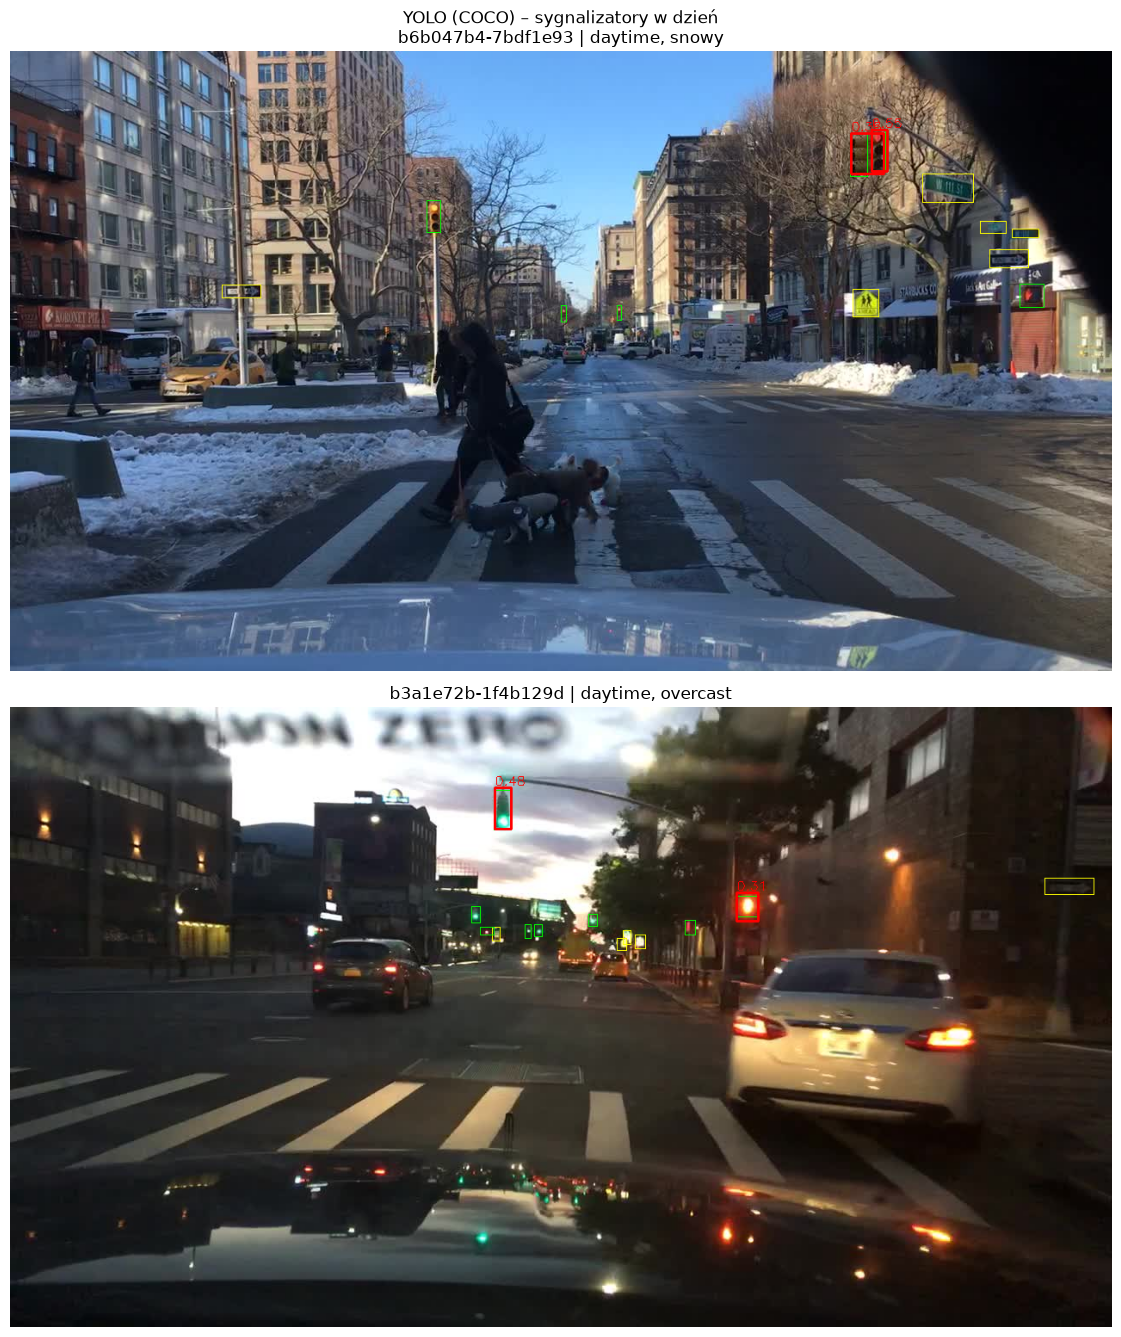

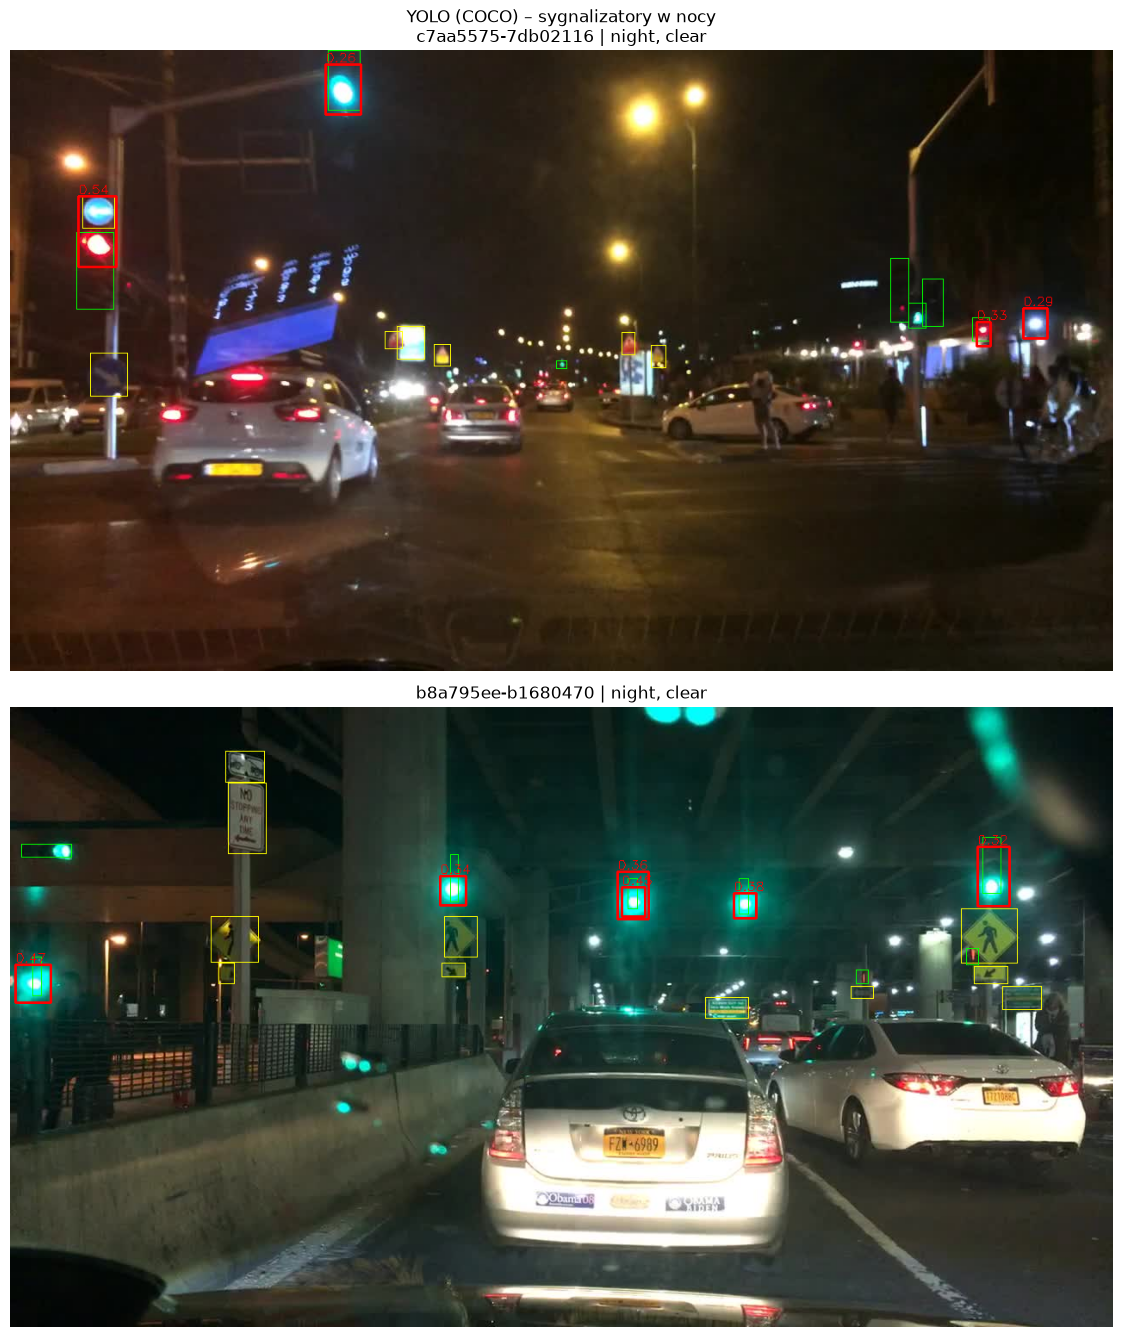

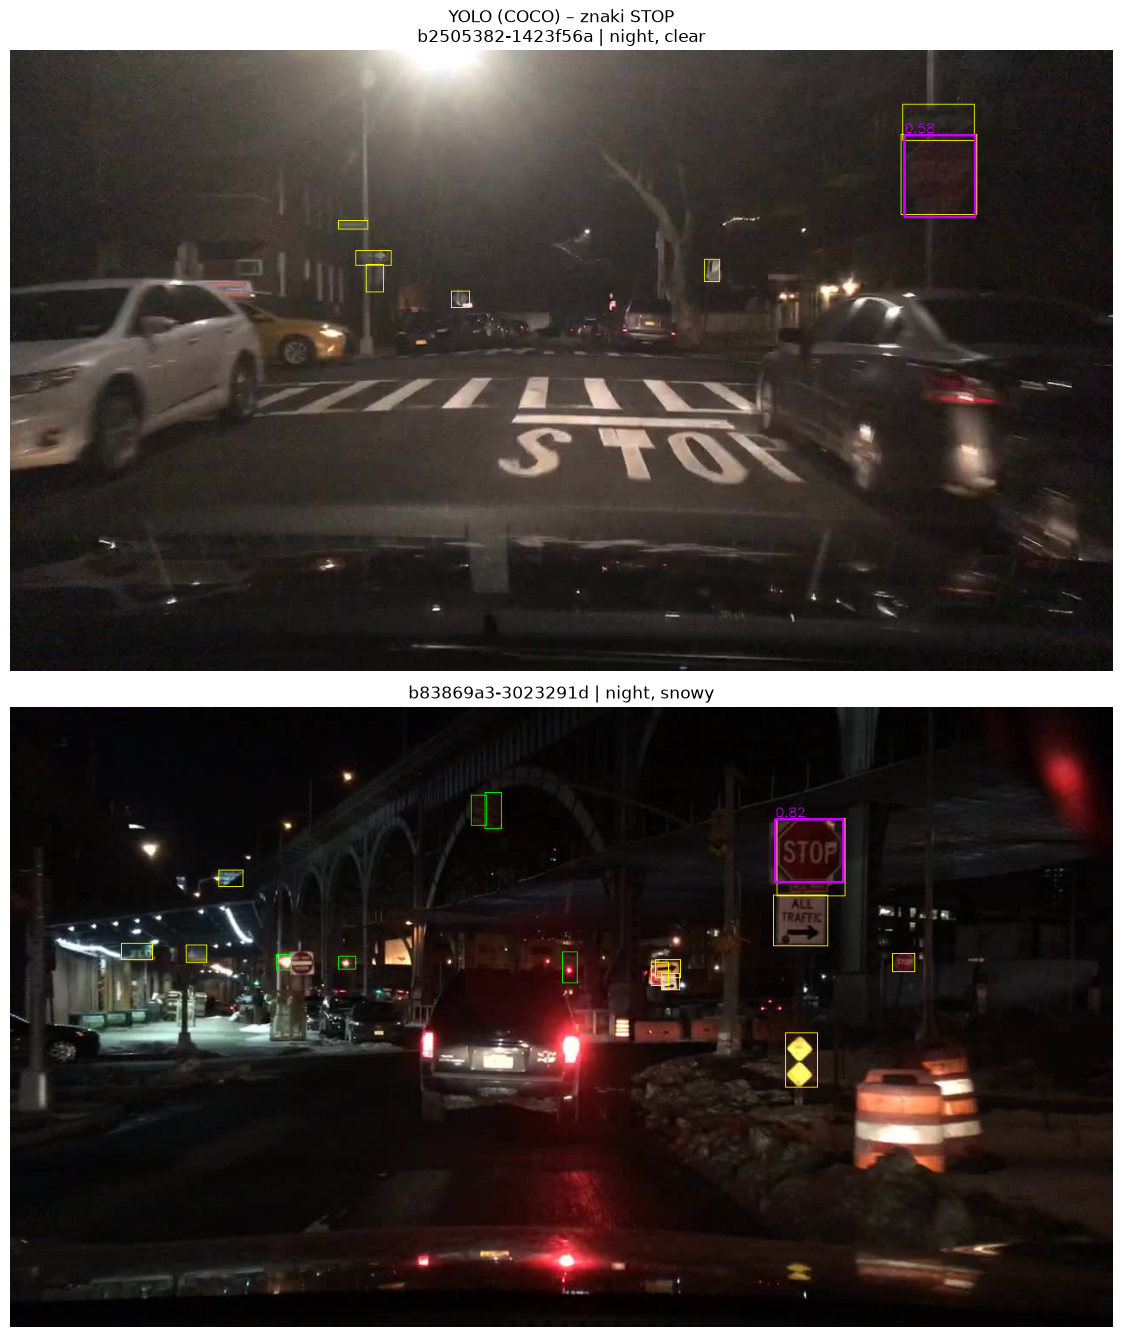

In [6]:
def read_rgb(name):
    return cv2.cvtColor(cv2.imread(ALL[name]["img_path"]), cv2.COLOR_BGR2RGB)


def draw_yolo(name, yolo_results, thr=0.25):
    vis = read_rgb(name)
    for b in ALL[name]["boxes"]:
        x1, y1, x2, y2 = map(int, b["box"])
        color = (0, 255, 0) if b["cls"] == "traffic_light" else (255, 255, 0)
        cv2.rectangle(vis, (x1, y1), (x2, y2), color, 1)
    r = yolo_results[name]
    for box, score, cls in zip(r["boxes"], r["scores"], r["classes"]):
        if score < thr:
            continue
        x1, y1, x2, y2 = map(int, box)
        color = (255, 0, 0) if cls == COCO_TRAFFIC_LIGHT else (200, 0, 255)
        cv2.rectangle(vis, (x1, y1), (x2, y2), color, 2)
        cv2.putText(vis, f"{score:.2f}", (x1, max(10, y1 - 3)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    return vis


def show_images(names, yolo_results, title, file_name=None):
    if not names:
        print("Brak obrazów:", title)
        return
    fig, axes = plt.subplots(len(names), 1, figsize=(12, 6.8 * len(names)), squeeze=False)
    for ax, name in zip(axes.ravel(), names):
        attrs = ALL[name]["attrs"]
        ax.imshow(draw_yolo(name, yolo_results))
        ax.set_title(f"{name} | {attrs.get('timeofday')}, {attrs.get('weather')}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    if file_name:
        save_figure(file_name)
    plt.show()


def images_with(yolo_results, coco_class, thr=0.25, **conditions):
    names = []
    for name in sorted(yolo_results):
        r = yolo_results[name]
        found = ((r["classes"] == coco_class) & (r["scores"] >= thr)).any()
        if found and all(ALL[name]["attrs"].get(k) == v for k, v in conditions.items()):
            names.append(name)
    return names


day = images_with(yolo_test_640, COCO_TRAFFIC_LIGHT, timeofday="daytime")
night = images_with(yolo_test_640, COCO_TRAFFIC_LIGHT, timeofday="night")
stops = images_with(yolo_test_640, COCO_STOP_SIGN)
show_images(random.sample(day, min(2, len(day))), yolo_test_640, "YOLO (COCO) – sygnalizatory w dzień", "yolo_coco_dzien")
show_images(random.sample(night, min(2, len(night))), yolo_test_640, "YOLO (COCO) – sygnalizatory w nocy", "yolo_coco_noc")
show_images(stops[:2], yolo_test_640, "YOLO (COCO) – znaki STOP", "yolo_coco_stop")

### 1.2 Znaki STOP a wszystkie znaki drogowe

Sprawdzono, jaką część znaków z adnotacji (`traffic_sign`) pokrywają detekcje klasy `stop sign`.

In [7]:
stop_result = evaluate(select(yolo_test_640, COCO_STOP_SIGN, 0.25), test, "traffic_sign")
n_signs = stop_result["TP"] + stop_result["FN"]
print(f"wykryte znaki STOP (pewność ≥ 0,25): {stop_result['TP'] + stop_result['FP']}")
print(f"  w tym zgodne ze znakiem z adnotacji (IoU ≥ 0,5): {stop_result['TP']}")
print(f"wszystkich znaków w zbiorze testowym: {n_signs}")
print(f"odsetek znaków wykrywalnych klasą stop sign: {stop_result['recall']:.1%}")

wykryte znaki STOP (pewność ≥ 0,25): 6
  w tym zgodne ze znakiem z adnotacji (IoU ≥ 0,5): 6
wszystkich znaków w zbiorze testowym: 1677
odsetek znaków wykrywalnych klasą stop sign: 0.4%


**Dlaczego model COCO nie wykrywa wszystkich znaków drogowych:**
- Model może zwrócić tylko klasy, które były w zbiorze treningowym. W COCO jedyną klasą znaku drogowego jest `stop sign`.
- W BDD100K klasa `traffic sign` obejmuje wszystkie znaki: zakazy, nakazy, ostrzeżenia, ograniczenia prędkości, tablice kierunkowe, nazwy ulic, a nawet tyły znaków. Większość z nich wygląda zupełnie inaczej niż ośmiokątny znak STOP.
- Inne znaki widoczne na zdjęciach COCO były tłem (bez etykiety), więc model wręcz uczył się ich nie wykrywać.
- Do wykrywania wszystkich znaków potrzebny jest fine-tuning na danych z klasą `traffic_sign` (wariant GPU). W wariancie CPU dalsza część dotyczy tylko sygnalizatorów.

## 2. Detekcja sygnalizatorów – wybór rozdzielczości i progu

**Rozumowanie:** domyślnie YOLO zmniejsza obraz do 640 px wzdłuż dłuższego boku. Ponieważ większość sygnalizatorów w BDD100K ma kilkanaście pikseli, po zmniejszeniu wiele z nich ma kilka pikseli i sieć nie jest w stanie ich rozpoznać. Model nie jest zmieniany – zmienia się tylko rozmiar obrazu podawanego na wejście, co nie jest fine-tuningiem.

**Eksperyment:** dla rozmiarów 640, 960 i 1280 px (1280 to pełna rozdzielczość zdjęcia) na zbiorze walidacyjnym:
1. dobierany jest próg pewności maksymalizujący F1,
2. mierzony jest czas działania.

Do dalszej części wybierany jest rozmiar z najwyższym F1 na zbiorze walidacyjnym.

In [8]:
CONF_GRID = [0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]


def tune_threshold(yolo_results, data):
    rows = []
    for thr in CONF_GRID:
        r = evaluate(select(yolo_results, COCO_TRAFFIC_LIGHT, thr), data)
        rows.append({"próg": thr, **{k: r[k] for k in METRICS}})
    grid = pd.DataFrame(rows)
    return float(grid.loc[grid.F1.idxmax(), "próg"]), grid


yolo_val, thresholds, grids, size_rows = {}, {}, {}, []
for imgsz in IMG_SIZES:
    yolo_val[imgsz] = load_or_compute(f"yolo_val_{imgsz}", run_yolo, val, imgsz)
    thresholds[imgsz], grids[imgsz] = tune_threshold(yolo_val[imgsz], val)
    best = grids[imgsz].set_index("próg").loc[thresholds[imgsz]]
    seconds = np.mean([r["seconds"] for r in yolo_val[imgsz].values()])
    size_rows.append({"rozmiar wejścia": imgsz, "próg pewności": thresholds[imgsz],
                      **{k: best[k] for k in METRICS}, "fps (CPU)": 1 / seconds})

size_table = pd.DataFrame(size_rows).set_index("rozmiar wejścia")
print("Sygnalizatory – zbiór walidacyjny, najlepszy próg dla każdego rozmiaru")
display(size_table.round(3))

BEST_SIZE = int(size_table.F1.idxmax())
YOLO_THR = thresholds[BEST_SIZE]
print(f"wybrany rozmiar wejścia: {BEST_SIZE} px, próg pewności: {YOLO_THR}")

YOLO 640:   0%|          | 0/500 [00:00<?, ?it/s]

YOLO 960:   0%|          | 0/500 [00:00<?, ?it/s]

YOLO 1280:   0%|          | 0/500 [00:00<?, ?it/s]

Sygnalizatory – zbiór walidacyjny, najlepszy próg dla każdego rozmiaru


,próg pewności,TP,FP,FN,precision,recall,F1,fps (CPU)
rozmiar wejścia,,,,,,,,
640,0.075,301.0,549.0,1043.0,0.354,0.224,0.274,6.775
960,0.100,421.0,517.0,923.0,0.449,0.313,0.369,4.473
1280,0.100,511.0,655.0,833.0,0.438,0.380,0.407,2.594


wybrany rozmiar wejścia: 1280 px, próg pewności: 0.1


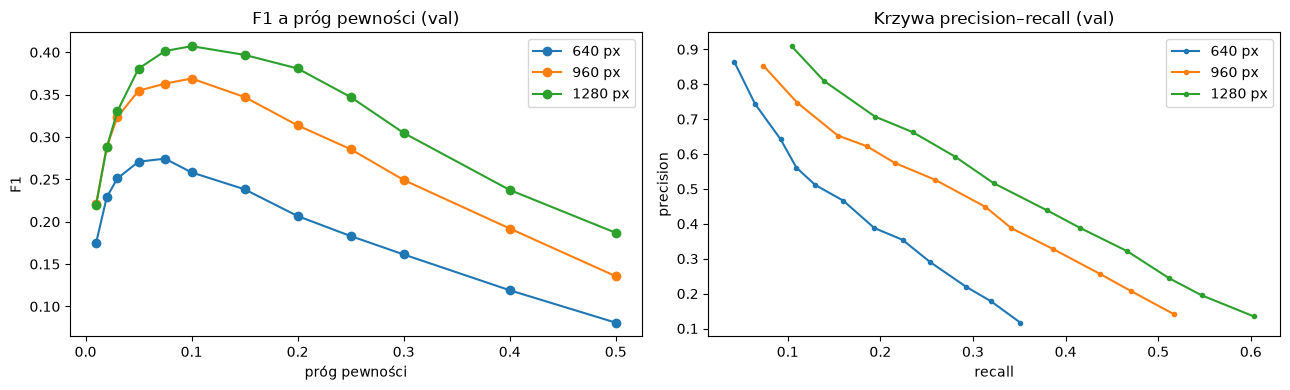

Recall w zależności od rozmiaru sygnalizatora (val):


,640 px,960 px,1280 px
size,,,
"(0, 8]",0.000,0.000,0.111
"(8, 16]",0.065,0.156,0.260
"(16, 32]",0.343,0.447,0.485
"(32, 64]",0.531,0.594,0.601
"(64, 1000]",0.600,0.400,0.400


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for imgsz in IMG_SIZES:
    g = grids[imgsz]
    axes[0].plot(g["próg"], g["F1"], marker="o", label=f"{imgsz} px")
    axes[1].plot(g["recall"], g["precision"], marker=".", label=f"{imgsz} px")
axes[0].set_xlabel("próg pewności")
axes[0].set_ylabel("F1")
axes[0].set_title("F1 a próg pewności (val)")
axes[0].legend()
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Krzywa precision–recall (val)")
axes[1].legend()
plt.tight_layout()
save_figure("yolo_rozdzielczosc_val")
plt.show()

recall_size_val = {}
for imgsz in IMG_SIZES:
    gt = evaluate(select(yolo_val[imgsz], COCO_TRAFFIC_LIGHT, thresholds[imgsz]), val)["gt"]
    recall_size_val[f"{imgsz} px"] = gt.groupby(pd.cut(gt["size"], [0, 8, 16, 32, 64, 1000]), observed=True)["found"].mean()
print("Recall w zależności od rozmiaru sygnalizatora (val):")
display(pd.DataFrame(recall_size_val).round(3))

**Na co patrzeć:** jeżeli hipoteza jest prawdziwa, przy większym rozmiarze wejścia rośnie przede wszystkim recall małych sygnalizatorów (8–32 px), a czas przetwarzania rośnie mniej więcej proporcjonalnie do liczby pikseli (1280 px to ok. 4 razy więcej pikseli niż 640 px).

## 3. Zadanie 2 – podejście hybrydowe: YOLO + kolor metodą klasyczną

YOLO zwraca ramkę sygnalizatora (ROI), a kolor określa metoda klasyczna. Rozważono trzy warianty:

1. **Reguły HSV.** W ramce wybierane są piksele świecące (S ≥ s_min, V ≥ v_min). Jeżeli stanowią mniej niż `min_frac` powierzchni ramki, wynikiem jest `unknown`. Dla każdego koloru liczone są świecące piksele w jego zakresie barwy (czerwony H < y_lo lub H ≥ 160, żółty y_lo ≤ H < y_hi, zielony 35–100). Najliczniejszy kolor musi mieć co najmniej `ratio` razy więcej pikseli niż drugi, w przeciwnym razie wynikiem jest `unknown`.
2. **Klasyfikator koloru z 2A** (gradient boosting) na cechach wycinka: histogram barwy świecących pikseli, udział świecących pikseli, średnie S i V, położenie świecącej plamy w ramce. Uczony na ramkach z adnotacji – dokładnie ta sama metoda co w laboratorium 2A.
3. **Ten sam klasyfikator uczony na ramkach YOLO.** Ramki z YOLO różnią się od ramek z adnotacji (inny margines, czasem tylko część obudowy). Klasyfikator uczony na ramkach z adnotacji widzi więc w teście inne dane niż w treningu. W tym wariancie na obrazach treningowych uruchamiany jest YOLO, a jego ramki dopasowane do sygnalizatorów z adnotacji (IoU ≥ 0,5) dostają kolor z adnotacji i służą jako dane treningowe.

Parametry reguł dobrano na ramkach YOLO z train. Wszystkie warianty porównano na ramkach YOLO z val (poprawnie zlokalizowanych), a wybrano wariant z najwyższą accuracy.

In [10]:
def crop(img, box):
    H, W = img.shape[:2]
    x1, y1, x2, y2 = box
    x1, y1 = int(max(0, x1)), int(max(0, y1))
    x2, y2 = int(min(W, np.ceil(x2))), int(min(H, np.ceil(y2)))
    return img[y1:max(y2, y1 + 1), x1:max(x2, x1 + 1)]


def color_by_rules(patch_hsv, s_min, v_min, min_frac, y_lo, y_hi, ratio):
    h, s, v = patch_hsv[..., 0], patch_hsv[..., 1], patch_hsv[..., 2]
    lit = (s >= s_min) & (v >= v_min)
    if lit.mean() < min_frac:
        return "unknown"
    hue = h[lit]
    counts = {
        "red": int(((hue < y_lo) | (hue >= 160)).sum()),
        "yellow": int(((hue >= y_lo) & (hue < y_hi)).sum()),
        "green": int(((hue >= 35) & (hue <= 100)).sum()),
    }
    ranked = sorted(counts, key=counts.get, reverse=True)
    first, second = counts[ranked[0]], counts[ranked[1]]
    if first == 0 or first < ratio * second:
        return "unknown"
    return ranked[0]


def lamp_position(v, lit):
    """Położenie świecącej plamy wzdłuż dłuższego boku ramki: 0 – góra/lewo, 1 – dół/prawo."""
    weights = v * lit
    if weights.sum() == 0:
        return 0.5
    h, w = v.shape
    if h >= w:
        coord = np.arange(h)[:, None] / max(h - 1, 1)
    else:
        coord = np.arange(w)[None, :] / max(w - 1, 1)
    return float((weights * coord).sum() / weights.sum())


def color_features(patch_hsv):
    h = patch_hsv[..., 0].astype(int)
    s = patch_hsv[..., 1].astype(float)
    v = patch_hsv[..., 2].astype(float)
    lit = (s >= 70) & (v >= 130)
    hue_hist = np.bincount((h[lit] // 10).clip(0, 17), minlength=18) / max(lit.sum(), 1)
    ph, pw = h.shape
    return np.r_[hue_hist, lit.mean(), s.mean() / 255, v.mean() / 255, (v > 200).mean(),
                 lamp_position(v, lit), ph / max(pw, 1)]


def gt_light_patches(data):
    """Wycinki HSV ramek sygnalizatorów z adnotacji i ich kolory."""
    patches = []
    for item in tqdm(data.values(), desc="wycinki z adnotacji"):
        gt, colors = gt_boxes(item, "traffic_light"), gt_colors(item)
        if len(gt) == 0:
            continue
        img = cv2.imread(item["img_path"])
        for box, color in zip(gt, colors):
            if box[2] - box[0] >= 1 and box[3] - box[1] >= 1:
                patches.append((cv2.cvtColor(crop(img, box), cv2.COLOR_BGR2HSV), color))
    return patches


def yolo_light_patches(yolo_results, data, thr):
    """Wycinki HSV ramek YOLO dopasowanych (IoU >= 0,5) do sygnalizatorów z adnotacji, z kolorem z adnotacji."""
    patches = []
    preds = select(yolo_results, COCO_TRAFFIC_LIGHT, thr)
    for name, pred in tqdm(preds.items(), desc="wycinki z YOLO"):
        item = data[name]
        gt = gt_boxes(item, "traffic_light")
        is_tp, matched_gt, _ = match(pred["boxes"], pred["scores"], gt)
        if not is_tp.any():
            continue
        img = cv2.imread(item["img_path"])
        colors = gt_colors(item)
        for i in np.where(is_tp)[0]:
            patches.append((cv2.cvtColor(crop(img, pred["boxes"][i]), cv2.COLOR_BGR2HSV), colors[matched_gt[i]]))
    return patches

Do zbudowania wariantu 3 YOLO uruchamiany jest na obrazach treningowych w wybranym rozmiarze wejścia. Przy rozmiarze 1280 px na CPU trwa to kilkanaście minut (wynik zapisywany jest w cache).

YOLO 1280:   0%|          | 0/2000 [00:00<?, ?it/s]

wycinki z YOLO:   0%|          | 0/2000 [00:00<?, ?it/s]

wycinki z YOLO:   0%|          | 0/500 [00:00<?, ?it/s]

wycinki treningowe: z adnotacji 5328, z YOLO 2057
wycinki walidacyjne z YOLO: 511
parametry reguł: {'s_min': 100.0, 'v_min': 160.0, 'min_frac': 0.01, 'y_lo': 15.0, 'y_hi': 26.0, 'ratio': 1.0}


,"accuracy (ramki YOLO, val)"
reguły HSV,0.755
klasyfikator – ramki z adnotacji (2A),0.881
klasyfikator – ramki YOLO,0.883


wybrana metoda koloru: klasyfikator – ramki YOLO


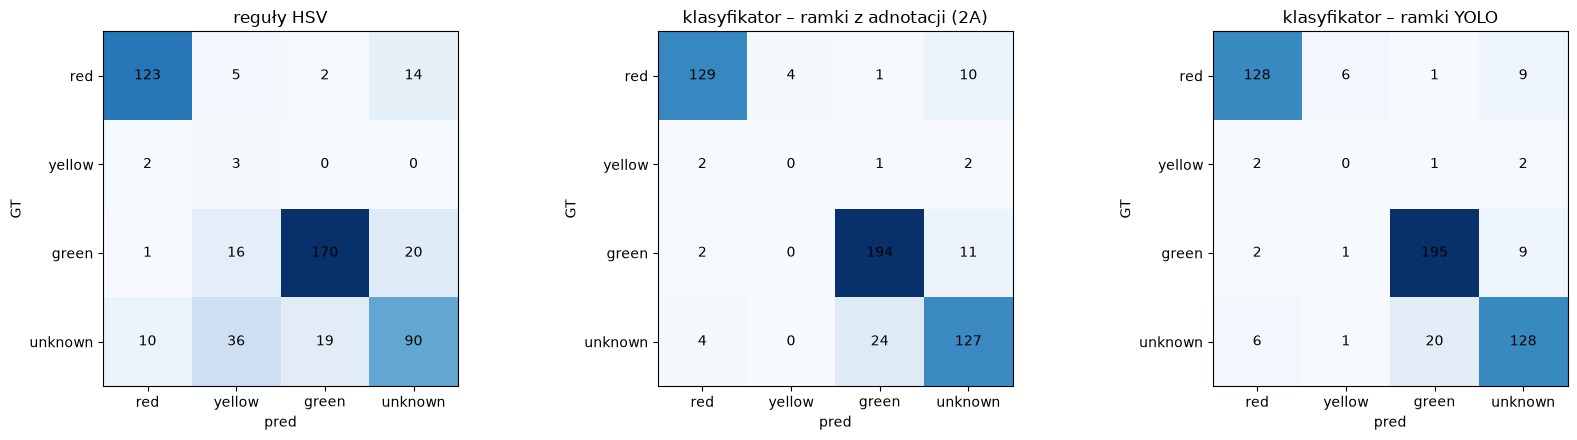

In [11]:
yolo_train = load_or_compute(f"yolo_train_{BEST_SIZE}", run_yolo, train, BEST_SIZE)

patches_gt_train = load_or_compute("color_patches_train", gt_light_patches, train)
patches_yolo_train = yolo_light_patches(yolo_train, train, YOLO_THR)
patches_yolo_val = yolo_light_patches(yolo_val[BEST_SIZE], val, YOLO_THR)
print(f"wycinki treningowe: z adnotacji {len(patches_gt_train)}, z YOLO {len(patches_yolo_train)}")
print(f"wycinki walidacyjne z YOLO: {len(patches_yolo_val)}")

y_val = np.array([c for _, c in patches_yolo_val])
y_yolo_train = np.array([c for _, c in patches_yolo_train])

# 1. reguły HSV – parametry dobrane na ramkach YOLO z train
param_grid = itertools.product((70, 100), (100, 130, 160), (0.01, 0.03, 0.06),
                               ((10, 35), (13, 30), (15, 26)), (1.0, 1.5, 2.0, 3.0))
rows = []
for s_min, v_min, min_frac, (y_lo, y_hi), ratio in param_grid:
    params = dict(s_min=s_min, v_min=v_min, min_frac=min_frac, y_lo=y_lo, y_hi=y_hi, ratio=ratio)
    pred = np.array([color_by_rules(p, **params) for p, _ in patches_yolo_train])
    rows.append({**params, "accuracy": np.mean(pred == y_yolo_train)})
P_COLOR = pd.DataFrame(rows).sort_values("accuracy", ascending=False).iloc[0].drop("accuracy").to_dict()
print("parametry reguł:", P_COLOR)

# 2. klasyfikator uczony na ramkach z adnotacji (jak w 2A)
clf_gt = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=SEED)
clf_gt.fit(np.array([color_features(p) for p, _ in patches_gt_train]), [c for _, c in patches_gt_train])

# 3. klasyfikator uczony na ramkach YOLO
clf_yolo = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced", random_state=SEED)
clf_yolo.fit(np.array([color_features(p) for p, _ in patches_yolo_train]), y_yolo_train)

X_val = np.array([color_features(p) for p, _ in patches_yolo_val])
color_preds_val = {
    "reguły HSV": np.array([color_by_rules(p, **P_COLOR) for p, _ in patches_yolo_val]),
    "klasyfikator – ramki z adnotacji (2A)": clf_gt.predict(X_val),
    "klasyfikator – ramki YOLO": clf_yolo.predict(X_val),
}
color_table = pd.DataFrame({name: {"accuracy (ramki YOLO, val)": np.mean(pred == y_val)}
                            for name, pred in color_preds_val.items()}).T
display(color_table.round(3))
COLOR_METHOD = color_table["accuracy (ramki YOLO, val)"].idxmax()
print("wybrana metoda koloru:", COLOR_METHOD)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, pred) in zip(axes, color_preds_val.items()):
    plot_confusion(ax, color_confusion(y_val, pred), name)
plt.tight_layout()
save_figure("kolor_warianty_val")
plt.show()

**Na co patrzeć:** jeżeli klasyfikator uczony na ramkach YOLO jest lepszy od klasyfikatora z 2A, to spadek trafności koloru w podejściu hybrydowym wynika z różnicy między ramkami z adnotacji a ramkami YOLO, a nie z samej metody rozpoznawania koloru.

In [12]:
def classify_color(img, box, method):
    patch_hsv = cv2.cvtColor(crop(img, box), cv2.COLOR_BGR2HSV)
    if method == "reguły HSV":
        return color_by_rules(patch_hsv, **P_COLOR)
    clf = clf_gt if method == "klasyfikator – ramki z adnotacji (2A)" else clf_yolo
    return clf.predict(color_features(patch_hsv)[None])[0]


def hybrid_predictions(yolo_results, data, thr, method):
    """Sygnalizatory z YOLO z kolorem określonym metodą klasyczną oraz średni czas koloru na obraz."""
    preds = select(yolo_results, COCO_TRAFFIC_LIGHT, thr)
    seconds = []
    for name, pred in preds.items():
        img = cv2.imread(data[name]["img_path"])
        start = time.perf_counter()
        pred["colors"] = [classify_color(img, box, method) for box in pred["boxes"]]
        seconds.append(time.perf_counter() - start)
    return preds, float(np.mean(seconds))

## 4. Zadanie 4 – porównanie z laboratorium 2A

Wszystkie warianty oceniane są na tych samych 500 obrazach testowych, tą samą funkcją i przy progu IoU ≥ 0,5. Zbiór testowy wykorzystano jednokrotnie, po wyborze wszystkich parametrów na train/val.

Porównywane warianty:
- **Lab 2A** – detektor klasyczny (kandydaci HSV/MSER, HOG + gradient boosting, regresja ramki) z kolorem z klasyfikatora; predykcje wczytywane z `predictions_test_lab2A.json`,
- **Lab 2B – wersja podstawowa** – YOLO 640 px (ustawienia domyślne) + kolor tą samą metodą co w 2A,
- **Lab 2B – wersja końcowa** – YOLO w rozmiarze wybranym na val + metoda koloru wybrana na val.

Czas działania: dla YOLO średni czas wywołania modelu i określenia koloru na obraz (CPU), dla 2A czas z pliku `fps_lab2A.json`, jeżeli istnieje.

In [13]:
with open("predictions_test_lab2A.json") as f:
    lab2A_raw = json.load(f)
lab2A_test = {}
for entry in lab2A_raw:
    lights = [l for l in entry["labels"] if l["category"].startswith("traffic_light")]
    lab2A_test[entry["name"]] = {
        "boxes": np.array([[l["box2d"][k] for k in ("x1", "y1", "x2", "y2")] for l in lights], np.float32).reshape(-1, 4),
        "scores": np.array([l["score"] for l in lights]),
        "colors": [l["category"].replace("traffic_light_", "") for l in lights],
    }

lab2A_fps = np.nan
if os.path.exists("fps_lab2A.json"):
    with open("fps_lab2A.json") as f:
        lab2A_fps = json.load(f)["fps"]
else:
    print("Brak pliku fps_lab2A.json – fps dla 2A pojawi się po uruchomieniu sekcji 'Czas działania' w notebooku 2A.")

yolo_test = {640: yolo_test_640}
if BEST_SIZE != 640:
    yolo_test[BEST_SIZE] = load_or_compute(f"yolo_test_{BEST_SIZE}", run_yolo, test, BEST_SIZE)

basic_preds, basic_color_s = hybrid_predictions(yolo_test[640], test, thresholds[640], "klasyfikator – ramki z adnotacji (2A)")
final_preds, final_color_s = hybrid_predictions(yolo_test[BEST_SIZE], test, YOLO_THR, COLOR_METHOD)


def yolo_fps(yolo_results, color_seconds):
    return 1 / (np.mean([r["seconds"] for r in yolo_results.values()]) + color_seconds)


VARIANTS = {
    "Lab 2A – metoda klasyczna": (lab2A_test, lab2A_fps),
    "Lab 2B – YOLO 640 px + kolor z 2A": (basic_preds, yolo_fps(yolo_test[640], basic_color_s)),
    f"Lab 2B – YOLO {BEST_SIZE} px + {COLOR_METHOD}": (final_preds, yolo_fps(yolo_test[BEST_SIZE], final_color_s)),
}
RESULTS = {}
rows = {}
for label, (preds, fps) in VARIANTS.items():
    RESULTS[label] = evaluate(preds, test)
    acc, n = color_accuracy(RESULTS[label])
    rows[label] = {**{k: RESULTS[label][k] for k in METRICS},
                   "accuracy koloru": acc, "TP do oceny koloru": n, "fps (CPU)": fps}
comparison = pd.DataFrame(rows).T
print("Sygnalizatory – zbiór testowy, IoU ≥ 0,5")
display(comparison.round(3))
comparison.to_csv("comparison_lab2A_lab2B.csv")

YOLO 1280:   0%|          | 0/500 [00:00<?, ?it/s]

Sygnalizatory – zbiór testowy, IoU ≥ 0,5


,TP,FP,FN,precision,recall,F1,accuracy koloru,TP do oceny koloru,fps (CPU)
Lab 2A – metoda klasyczna,355.0,855.0,1066.0,0.293,0.250,0.270,0.910,355.0,0.501
Lab 2B – YOLO 640 px + kolor z 2A,315.0,648.0,1106.0,0.327,0.222,0.264,0.838,315.0,5.518
Lab 2B – YOLO 1280 px + klasyfikator – ramki YOLO,519.0,745.0,902.0,0.411,0.365,0.387,0.846,519.0,2.240


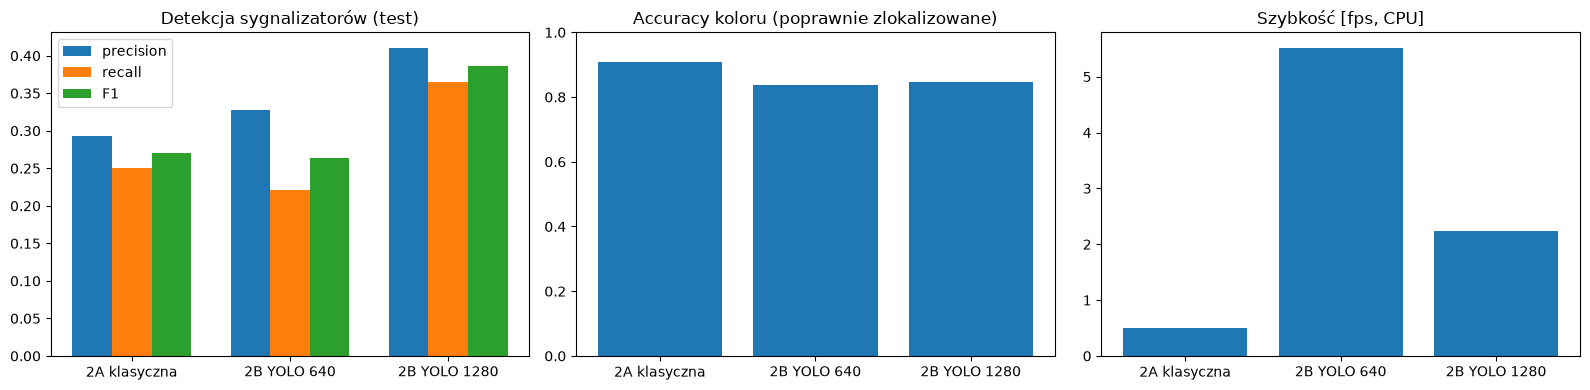

In [14]:
labels = list(VARIANTS)
short = ["2A klasyczna", "2B YOLO 640", f"2B YOLO {BEST_SIZE}"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(3)
for k, metric in enumerate(["precision", "recall", "F1"]):
    axes[0].bar(x + (k - 1) * 0.25, comparison.loc[labels, metric], width=0.25, label=metric)
axes[0].set_xticks(x, short)
axes[0].set_title("Detekcja sygnalizatorów (test)")
axes[0].legend()
axes[1].bar(short, comparison.loc[labels, "accuracy koloru"])
axes[1].set_ylim(0, 1)
axes[1].set_title("Accuracy koloru (poprawnie zlokalizowane)")
axes[2].bar(short, comparison.loc[labels, "fps (CPU)"].fillna(0))
axes[2].set_title("Szybkość [fps, CPU]")
plt.tight_layout()
save_figure("porownanie_2A_2B")
plt.show()

### 4.1 Gdzie które podejście jest lepsze

Łączne metryki mogą ukrywać różnice. Recall rozbito na rozmiar sygnalizatora i porę dnia.

Recall w zależności od rozmiaru sygnalizatora [px]:


,2A klasyczna,2B YOLO 640,2B YOLO 1280
size,,,
"(0, 8]",0.000,0.000,0.000
"(8, 16]",0.233,0.053,0.264
"(16, 32]",0.287,0.310,0.449
"(32, 64]",0.246,0.524,0.503
"(64, 1000]",0.091,0.727,0.545


Recall w zależności od pory dnia:


,2A klasyczna,2B YOLO 640,2B YOLO 1280
timeofday,,,
dawn/dusk,0.172,0.338,0.444
daytime,0.193,0.245,0.404
night,0.318,0.175,0.314


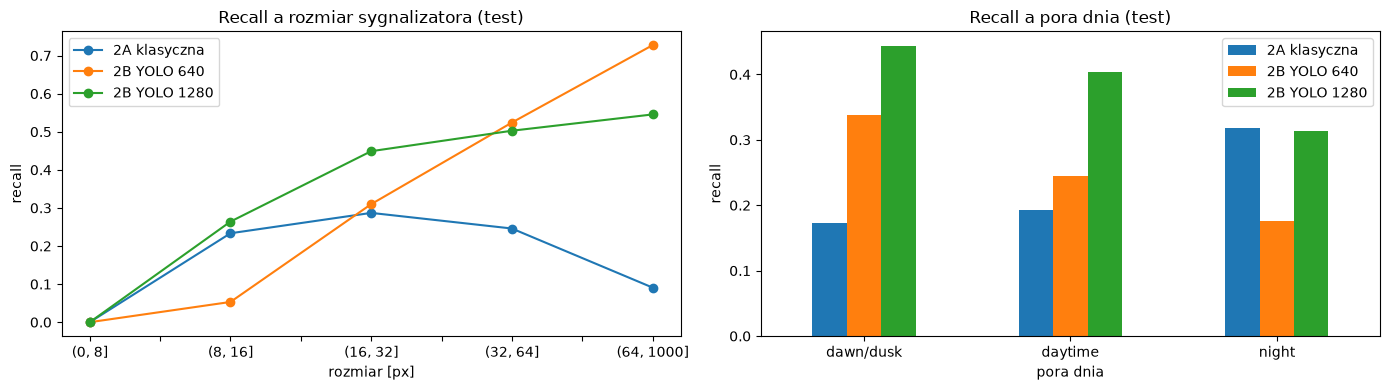

In [15]:
by_size, by_time = {}, {}
for label, s in zip(labels, short):
    gt = RESULTS[label]["gt"]
    by_size[s] = gt.groupby(pd.cut(gt["size"], [0, 8, 16, 32, 64, 1000]), observed=True)["found"].mean()
    by_time[s] = gt.groupby("timeofday")["found"].mean()
by_size, by_time = pd.DataFrame(by_size), pd.DataFrame(by_time)
print("Recall w zależności od rozmiaru sygnalizatora [px]:")
display(by_size.round(3))
print("Recall w zależności od pory dnia:")
display(by_time.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_size.plot(ax=axes[0], marker="o", title="Recall a rozmiar sygnalizatora (test)")
axes[0].set_xlabel("rozmiar [px]")
axes[0].set_ylabel("recall")
by_time.plot.bar(ax=axes[1], title="Recall a pora dnia (test)", rot=0)
axes[1].set_xlabel("pora dnia")
axes[1].set_ylabel("recall")
plt.tight_layout()
save_figure("recall_rozmiar_pora_dnia")
plt.show()

### 4.2 Czy podejścia się uzupełniają?

Jeżeli metoda klasyczna i YOLO wykrywają w dużej mierze różne sygnalizatory, połączenie obu dałoby wyraźnie wyższy recall. Policzono, ile sygnalizatorów z adnotacji wykrywa tylko jedna z metod, a ile obie.

In [16]:
found_2A = RESULTS[labels[0]]["gt"]["found"].to_numpy()
found_yolo = RESULTS[labels[2]]["gt"]["found"].to_numpy()
overlap = pd.Series({
    "wykryte przez obie metody": int((found_2A & found_yolo).sum()),
    "tylko metoda klasyczna (2A)": int((found_2A & ~found_yolo).sum()),
    f"tylko YOLO {BEST_SIZE} px": int((~found_2A & found_yolo).sum()),
    "przez żadną": int((~found_2A & ~found_yolo).sum()),
}, name="liczba sygnalizatorów")
display(overlap.to_frame())
print(f"recall, gdyby wykrycie przez dowolną z metod liczyło się jako sukces: {(found_2A | found_yolo).mean():.3f}")

,liczba sygnalizatorów
wykryte przez obie metody,204
tylko metoda klasyczna (2A),151
tylko YOLO 1280 px,315
przez żadną,751


recall, gdyby wykrycie przez dowolną z metod liczyło się jako sukces: 0.471


### 4.3 Kolor – macierze pomyłek (test)

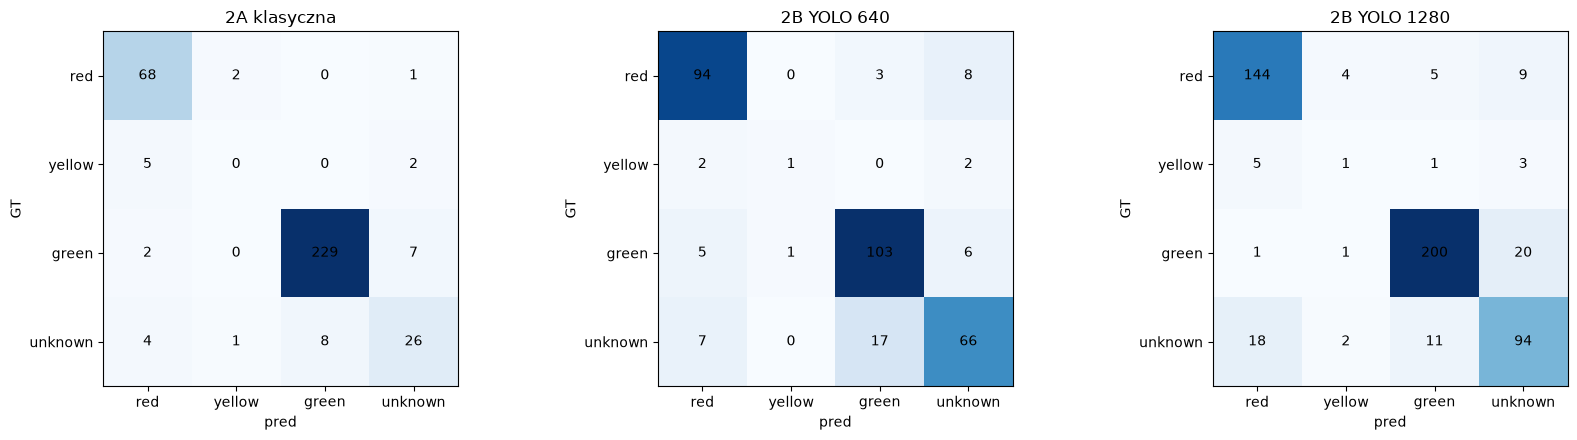

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, label, s in zip(axes, labels, short):
    c = RESULTS[label]["colors"]
    plot_confusion(ax, color_confusion(c["gt"], c["pred"]) if len(c) else color_confusion([], []), s)
plt.tight_layout()
save_figure("kolor_test")
plt.show()

### Zapis wyników

In [18]:
output = []
for name in sorted(test):
    pred = final_preds[name]
    labels_out = []
    for box, score, color in zip(pred["boxes"], pred["scores"], pred["colors"]):
        x1, y1, x2, y2 = map(float, box)
        labels_out.append({"category": f"traffic_light_{color}", "score": float(score),
                           "box2d": {"x1": x1, "y1": y1, "x2": x2, "y2": y2}})
    output.append({"name": name, "labels": labels_out})
with open("predictions_test_lab2B.json", "w") as f:
    json.dump(output, f, indent=1)

key_numbers = {
    "rozmiar wejścia YOLO": BEST_SIZE,
    "próg pewności YOLO": YOLO_THR,
    "metoda koloru": COLOR_METHOD,
    "znaki STOP – odsetek wszystkich znaków": stop_result["recall"],
    **{f"{s} – {k}": float(comparison.loc[label, k])
       for label, s in zip(labels, short) for k in ("precision", "recall", "F1", "accuracy koloru", "fps (CPU)")},
}
with open("summary_lab2B.json", "w") as f:
    json.dump(key_numbers, f, indent=1, ensure_ascii=False)
print("Zapisano: predictions_test_lab2B.json, comparison_lab2A_lab2B.csv, summary_lab2B.json, wykresy w", FIG_DIR)

Zapisano: predictions_test_lab2B.json, comparison_lab2A_lab2B.csv, summary_lab2B.json, wykresy w figures


## 5. Zadanie 5 – przykłady błędów (wersja końcowa)

- **False positives:** detekcje z najwyższą pewnością, które nie pasują do żadnego sygnalizatora z adnotacji.
- **False negatives:** losowe niewykryte sygnalizatory o rozmiarze powyżej mediany (pomijane są najmniejsze, bo ich nie wykrywa żadna metoda).
- **Błędy koloru:** poprawnie zlokalizowane sygnalizatory z błędnie określonym kolorem.

Zielone cienkie ramki – sygnalizatory z adnotacji, czerwona lub fioletowa gruba ramka – opisywany przypadek.

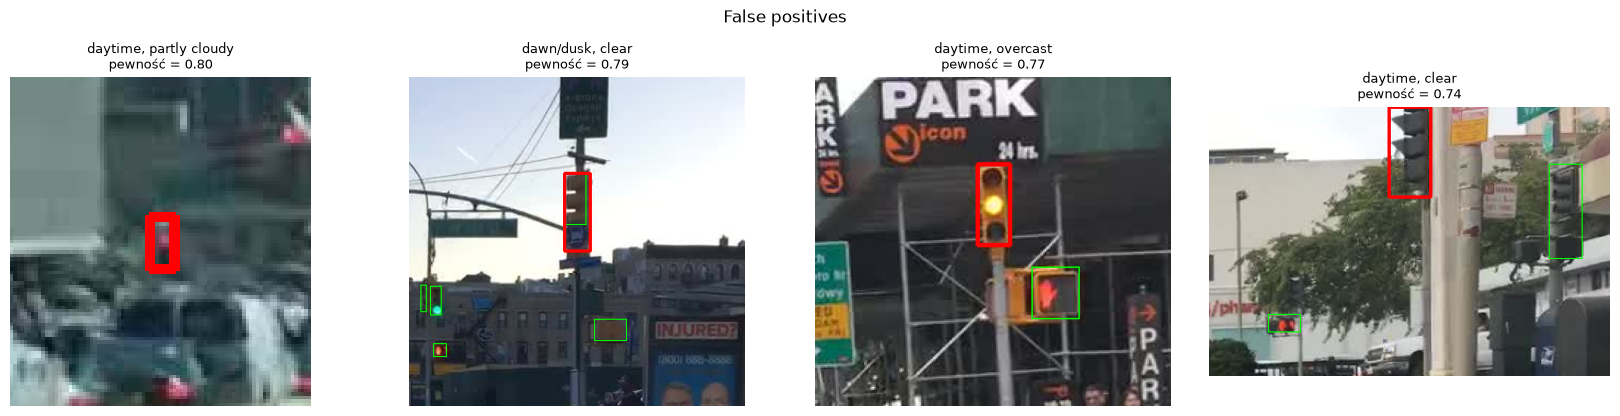

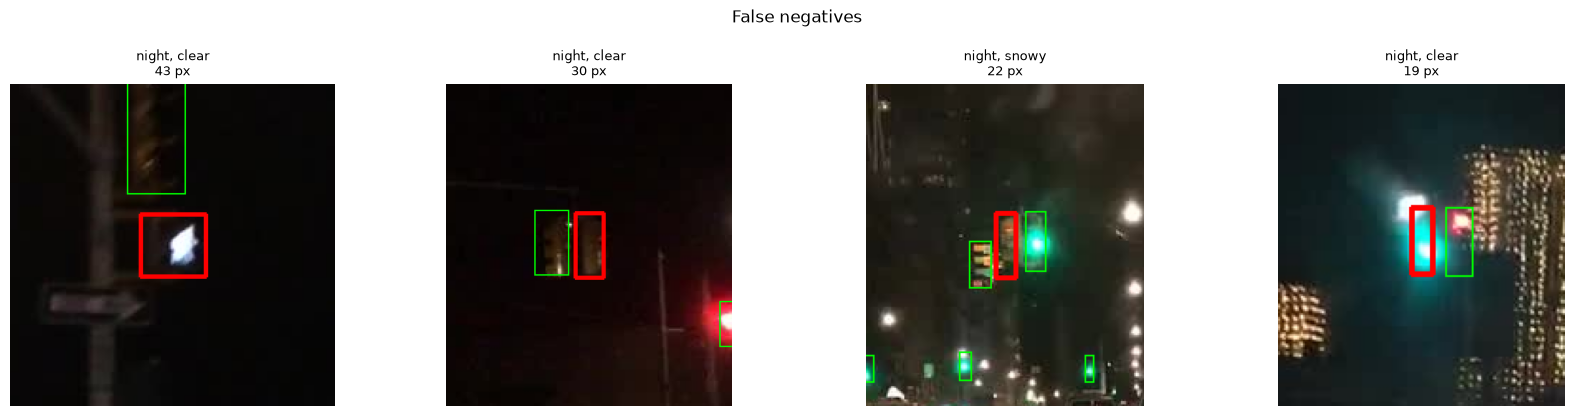

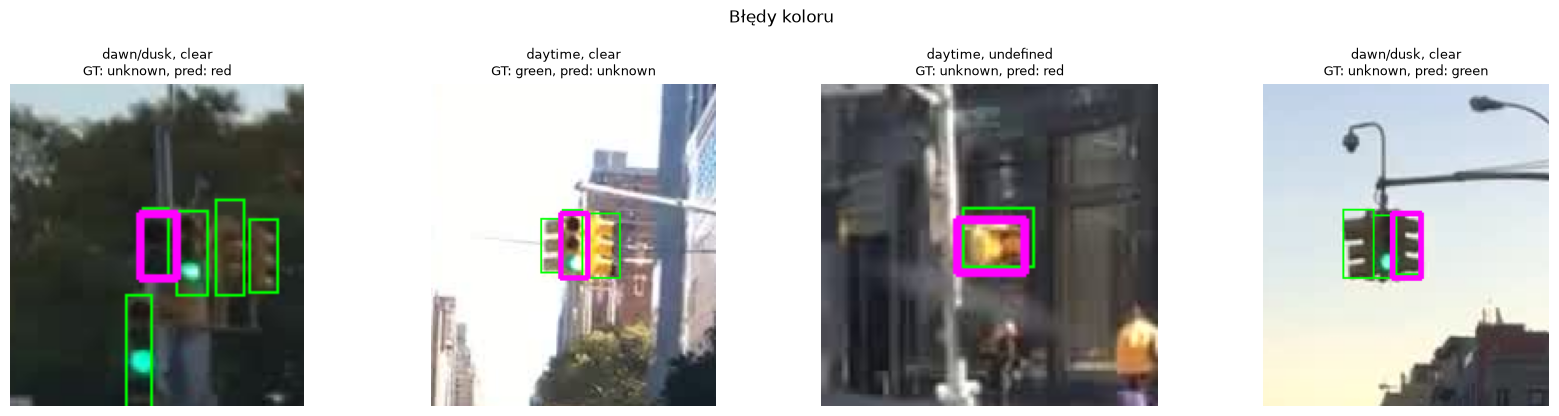

In [19]:
def draw_gt_lights(img, item):
    img = img.copy()
    for b in item["boxes"]:
        if b["cls"] == "traffic_light":
            x1, y1, x2, y2 = map(int, b["box"])
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 1)
    return img


def show_errors(examples, title, file_name, box_color=(255, 0, 0)):
    """examples: lista (nazwa obrazu, ramka, podpis)."""
    if not examples:
        print("Brak przykładów:", title)
        return
    fig, axes = plt.subplots(1, len(examples), figsize=(4.2 * len(examples), 4.2), squeeze=False)
    for ax, (name, box, caption) in zip(axes.ravel(), examples):
        vis = draw_gt_lights(read_rgb(name), ALL[name])
        x1, y1, x2, y2 = map(int, box)
        cv2.rectangle(vis, (x1, y1), (x2, y2), box_color, 2)
        m = int(max(40, 2 * max(x2 - x1, y2 - y1)))
        ax.imshow(vis[max(0, y1 - m):y2 + m, max(0, x1 - m):x2 + m])
        attrs = ALL[name]["attrs"]
        ax.set_title(f"{attrs.get('timeofday')}, {attrs.get('weather')}\n{caption}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    save_figure(file_name)
    plt.show()


final = RESULTS[labels[2]]
rng_errors = random.Random(SEED)

top_fp = sorted(final["fp"], key=lambda e: -e[2])[:4]
show_errors([(n, b, f"pewność = {s:.2f}") for n, b, s in top_fp], "False positives", "bledy_fp")

median_size = final["gt"]["size"].median() if len(final["gt"]) else 0
large_fn = [(n, b) for n, b in final["fn"] if box_size(b) >= median_size]
sampled_fn = rng_errors.sample(large_fn, min(4, len(large_fn)))
show_errors([(n, b, f"{box_size(b):.0f} px") for n, b in sampled_fn], "False negatives", "bledy_fn")

c = final["colors"]
wrong = c[c["gt"] != c["pred"]] if len(c) else c
wrong = wrong.sample(min(4, len(wrong)), random_state=SEED) if len(wrong) else wrong
show_errors([(r.image, r.box, f"GT: {r.gt}, pred: {r.pred}") for r in wrong.itertuples()],
            "Błędy koloru", "bledy_kolor", box_color=(255, 0, 255))

### Przyczyny błędów

Do uzupełnienia na podstawie powyższych przykładów.

## 6. Wnioski

Do uzupełnienia po uruchomieniu.